# 06 - Avaliação dos Modelos (métricas da Aula 08)

Avaliação final no **conjunto de teste** (usado aqui pela primeira vez) e também no
treino, para a análise de generalização (notebook 07).

| Problema | Métricas |
|---|---|
| Regressão | MAE, MSE, RMSE, MAPE, R², MedAE |
| Classificação | Matriz de confusão, Accuracy, Precision, Recall, F1, ROC-AUC, PR-AUC |

O problema de classificação é **binário** (doença: sim/não), então Precision, Recall e
F1 são calculados para a classe positiva (com doença); médias macro/weighted não se aplicam.

In [1]:
import sys
sys.path.insert(0, "..")
import warnings
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import ConfusionMatrixDisplay, PrecisionRecallDisplay, RocCurveDisplay

from src.config import carregar_split, salvar_fig, salvar_tabela
from src.metrics import metricas_classificacao, metricas_regressao
from src.models import carregar_modelos, pontuacao

sns.set_style("whitegrid")

## 1. Classificação

In [2]:
X_train, X_test, y_train, y_test = carregar_split("classificacao")
modelos = carregar_modelos("classificacao")
print(f"Classe positiva (doença) - treino: {y_train.mean():.1%} | teste: {y_test.mean():.1%}")

linhas, preds, scores = [], {}, {}
for nome, m in modelos.items():
    for conjunto, X, y in [("treino", X_train, y_train), ("teste", X_test, y_test)]:
        pred, score = m.predict(X), pontuacao(m, X)
        linhas.append({"modelo": nome, "conjunto": conjunto, **metricas_classificacao(y, pred, score)})
        if conjunto == "teste":
            preds[nome], scores[nome] = pred, score
met_c = pd.DataFrame(linhas)
salvar_tabela(met_c, "metricas_classificacao", index=False)
met_c.query("conjunto == 'teste'").set_index("modelo").drop(columns="conjunto").round(4)

Classe positiva (doença) - treino: 30.3% | teste: 30.3%


,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
modelo,,,,,,
Sistema Especialista,0.8339,0.7165,0.7468,0.7314,0.8976,0.8157
Árvore (sem restrição),0.8278,0.7308,0.6826,0.7059,0.7867,0.5950
Árvore (ajustada),0.8567,0.7808,0.7321,0.7557,0.8848,0.7931
Random Forest,0.8756,0.8000,0.7853,0.7926,0.9394,0.8843
Gradient Boosting,0.8894,0.8545,0.7651,0.8074,0.9451,0.9006


In [3]:
# Referência: classificador trivial que sempre prevê "sem doença"
trivial = metricas_classificacao(y_test, np.zeros(len(y_test)))
print("Baseline 'sempre sem doença':", {k: round(v, 4) for k, v in trivial.items()})

Baseline 'sempre sem doença': {'Accuracy': 0.6972, 'Precision': 0.0, 'Recall': 0.0, 'F1': 0.0, 'ROC-AUC': nan, 'PR-AUC': nan}


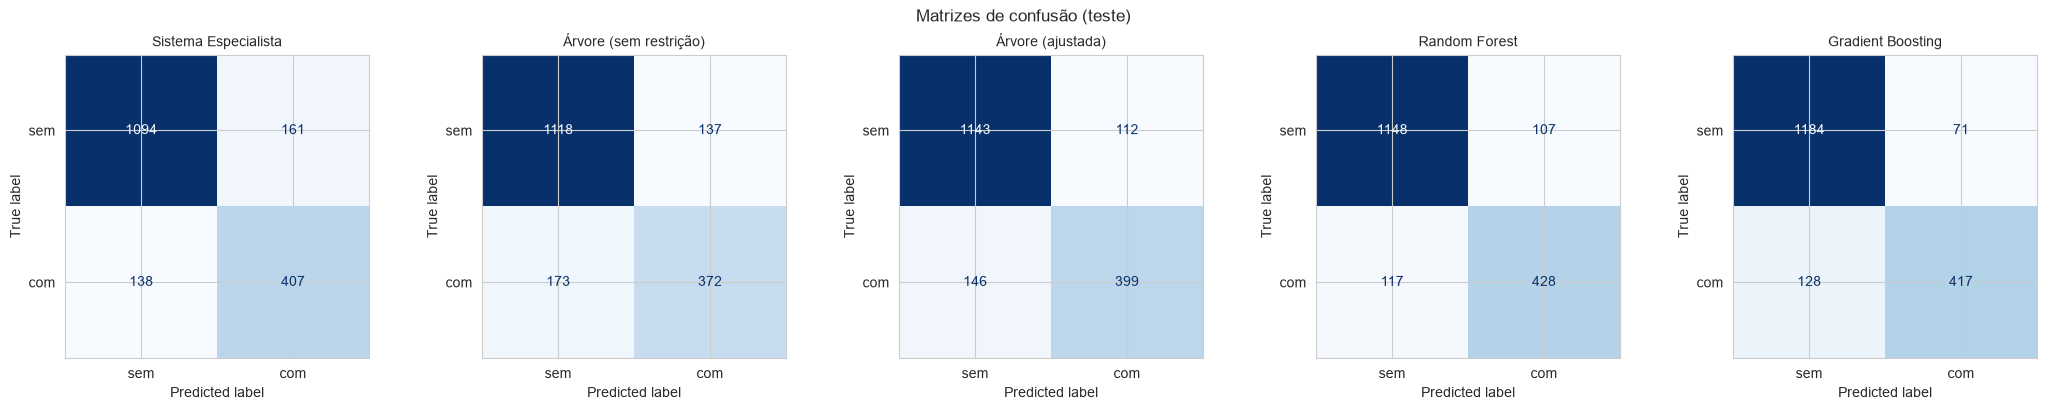

In [4]:
fig, axes = plt.subplots(1, len(modelos), figsize=(4.2 * len(modelos), 4))
for ax, (nome, pred) in zip(axes, preds.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["sem", "com"],
                                            cmap="Blues", colorbar=False, ax=ax)
    ax.set_title(nome, fontsize=10)
plt.suptitle("Matrizes de confusão (teste)")
plt.tight_layout()
salvar_fig("matrizes_confusao")
plt.show()

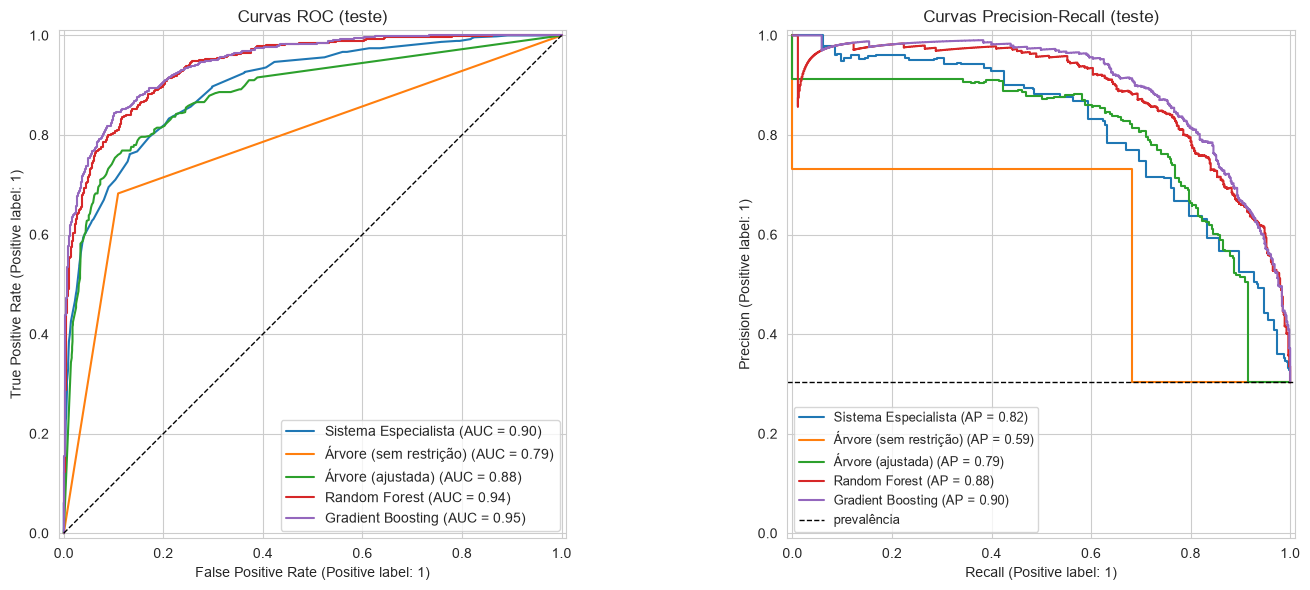

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for nome, s in scores.items():
    if s is None:
        print(f"{nome}: sem pontuação contínua -> sem curva ROC/PR")
        continue
    RocCurveDisplay.from_predictions(y_test, s, name=nome, ax=axes[0])
    PrecisionRecallDisplay.from_predictions(y_test, s, name=nome, ax=axes[1])
axes[0].plot([0, 1], [0, 1], "k--", lw=1)
axes[1].axhline(y_test.mean(), ls="--", c="k", lw=1, label="prevalência")
axes[0].set_title("Curvas ROC (teste)")
axes[1].set_title("Curvas Precision-Recall (teste)")
axes[1].legend(loc="lower left", fontsize=9)
plt.tight_layout()
salvar_fig("curvas_roc_pr")
plt.show()

**Pontuação do sistema especialista:** as regras produzem uma decisão discreta (0/1),
que gera um único ponto no espaço ROC. Para obter uma curva é preciso uma pontuação
contínua: se a base de regras acumula um fato `score` (cada evidência de risco soma um
peso), esse valor é usado como pontuação e as curvas são traçadas variando o limiar.
Ele **não é uma probabilidade calibrada** (os pesos são definidos pelo especialista),
mas serve para ordenar os pacientes, que é o que ROC-AUC e PR-AUC medem. Sem esse fato,
ROC-AUC/PR-AUC do especialista ficam indefinidos.

## 2. Regressão

In [6]:
X_train, X_test, y_train, y_test = carregar_split("regressao")
modelos = carregar_modelos("regressao")

linhas, preds_r = [], {}
for nome, m in modelos.items():
    for conjunto, X, y in [("treino", X_train, y_train), ("teste", X_test, y_test)]:
        pred = m.predict(X)
        linhas.append({"modelo": nome, "conjunto": conjunto, **metricas_regressao(y, pred)})
        if conjunto == "teste":
            preds_r[nome] = pred
met_r = pd.DataFrame(linhas)
salvar_tabela(met_r, "metricas_regressao", index=False)
met_r.query("conjunto == 'teste'").set_index("modelo").drop(columns="conjunto").round(4)

,MAE,MSE,RMSE,MAPE (%),R2,MedAE
modelo,,,,,,
Sistema Especialista,9.9368,158.2719,12.5806,6.1923,0.6554,8.4000
Árvore (sem restrição),13.2433,280.6344,16.7521,8.2586,0.3889,11.0000
Árvore (ajustada),9.7777,151.2270,12.2974,6.1338,0.6707,8.1477
Random Forest,9.6668,147.0951,12.1283,6.0650,0.6797,8.1841
Gradient Boosting,9.5880,145.7755,12.0738,6.0100,0.6826,8.0430


In [7]:
baseline = metricas_regressao(y_test, np.full(len(y_test), y_train.mean()))
print("Baseline 'prever a média do treino':", {k: round(v, 4) for k, v in baseline.items()})

Baseline 'prever a média do treino': {'MAE': 17.4771, 'MSE': 459.3577, 'RMSE': np.float64(21.4326), 'MAPE (%)': 11.1378, 'R2': -0.0002, 'MedAE': 15.0957}


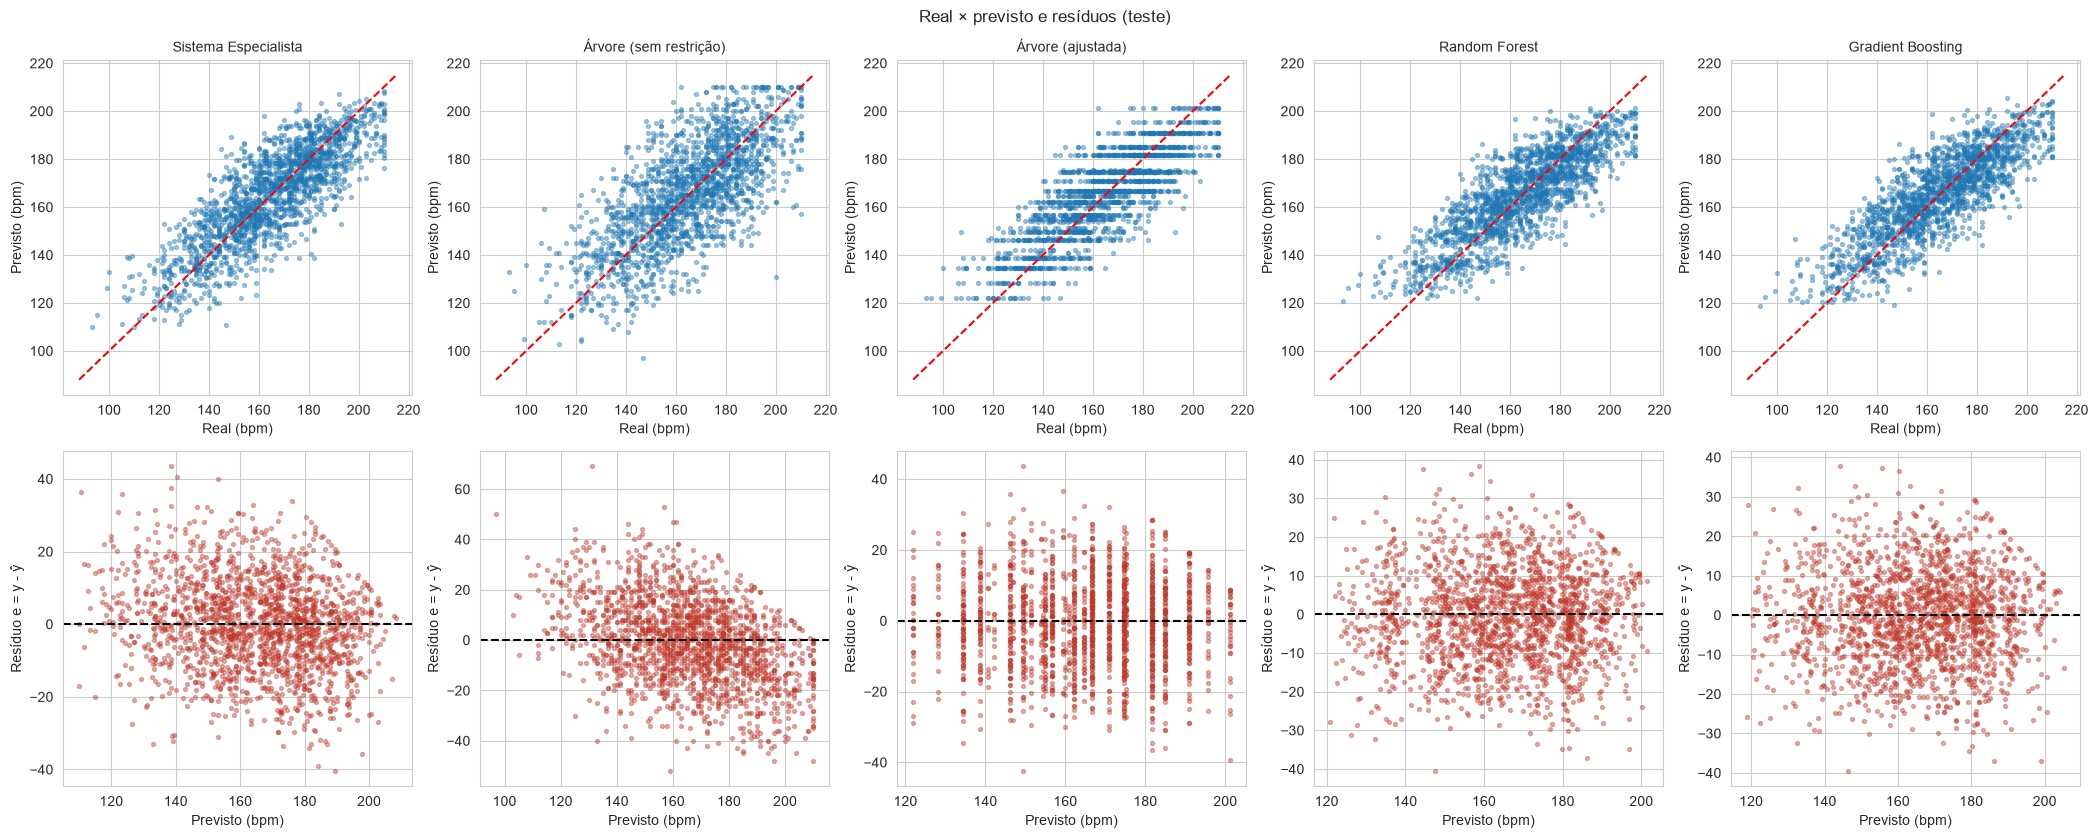

In [8]:
fig, axes = plt.subplots(2, len(modelos), figsize=(4.2 * len(modelos), 8.5))
lim = [y_test.min() - 5, y_test.max() + 5]
for j, (nome, pred) in enumerate(preds_r.items()):
    axes[0, j].scatter(y_test, pred, s=8, alpha=0.4)
    axes[0, j].plot(lim, lim, "r--")
    axes[0, j].set_title(nome, fontsize=10)
    axes[0, j].set_xlabel("Real (bpm)")
    axes[0, j].set_ylabel("Previsto (bpm)")
    res = y_test - pred
    axes[1, j].scatter(pred, res, s=8, alpha=0.4, c="#c0392b")
    axes[1, j].axhline(0, c="k", ls="--")
    axes[1, j].set_xlabel("Previsto (bpm)")
    axes[1, j].set_ylabel("Resíduo e = y - ŷ")
plt.suptitle("Real × previsto e resíduos (teste)")
plt.tight_layout()
salvar_fig("residuos_regressao")
plt.show()

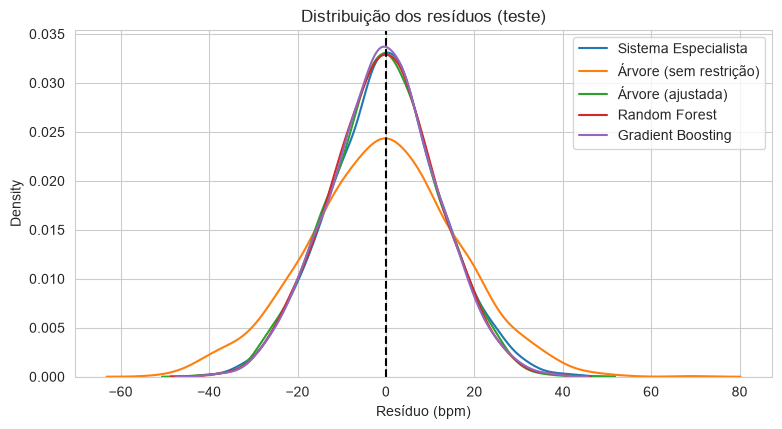

,count,mean,std,min,25%,50%,75%,max
Sistema Especialista,1800.0,-0.11,12.58,-40.40,-8.70,0.00,7.90,43.40
Árvore (sem restrição),1800.0,-0.76,16.74,-52.00,-12.00,-1.00,10.00,69.00
Árvore (ajustada),1800.0,-0.65,12.28,-42.42,-8.84,-0.56,7.40,43.58
Random Forest,1800.0,-0.59,12.12,-40.51,-8.61,-0.49,7.66,38.27
Gradient Boosting,1800.0,-0.56,12.06,-39.51,-8.56,-0.55,7.36,37.67


In [9]:
fig, ax = plt.subplots(figsize=(9, 4.5))
for nome, pred in preds_r.items():
    sns.kdeplot(y_test - pred, label=nome, ax=ax)
ax.axvline(0, c="k", ls="--")
ax.set_xlabel("Resíduo (bpm)")
ax.set_title("Distribuição dos resíduos (teste)")
ax.legend()
salvar_fig("residuos_distribuicao")
plt.show()
pd.DataFrame({n: pd.Series(y_test.values - p).describe() for n, p in preds_r.items()}).T.round(2)